# critflaw showcase

> **⚠️ Research software in development. Not verified or validated. Do not use for any real engineering
> decision, design, fitness-for-service, safety case or regulatory submission.** See `DISCLAIMER.md`.

A tour of the library on one welded plate with a surface-breaking flaw, told mostly through the
**failure assessment diagram (FAD)**, the graphical heart of the method:

| | |
|---|---|
| **1. Assess** | the FAD: Option 1 and Option 2 lines, the assessment point, the load ray |
| **2. Map** | 14 400 assessments in one vectorised call: where is this flaw acceptable? |
| **3. Margins** | reserve factors and the limiting flaw size, as paths across the FAD |
| **4. Probability** | the assessment point as a **probability-density field** on the FAD |
| **5. Uncertain line** | the **exceedance field** of a scattered assessment line, overlaid with the point density |
| **6. Grow** | fatigue **trajectories** across the FAD, and a population **marching towards the line** |
| **7. Over the life** | time-dependent failure probability, with and without an inspection |
| **8. Audit** | the trace: every equation, its reference and its verification status |

All inputs are **illustrative** SI values (Pa, m, Pa m^0.5), not taken from any standard's worked example.
The graphics come from `critflaw.plot`; the methods are in `docs/manual/theory/`.

In [1]:
import textwrap
import time

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import TwoSlopeNorm

import critflaw as cf
from critflaw import plot as fadplot
from critflaw import prob
from critflaw.fatigue import ExtremeLoad, Inspection, Spectrum, TimeDependentAssessment, steel_in_air
from critflaw.fatigue.growth import SURFACE
from critflaw.prob.inspection import LogLogisticPoD

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
T0 = time.perf_counter()

## 1. Assess: one flaw, one call, one diagram

A 25 mm plate of a C-Mn steel with a 3 mm deep, 20 mm long surface flaw under 150 MPa membrane and 30 MPa
bending stress. Problems are immutable objects; `run()` returns the assessment point, the acceptance decision
(the direct test `Kr < f(Lr)` and `Lr < Lr,max` at every crack-front position) and the margins.

Lr = 0.469   Kr = 0.194   Lr,max = 1.190
governing position: deepest
acceptable: True   radial margin (load factor to the line): 2.24


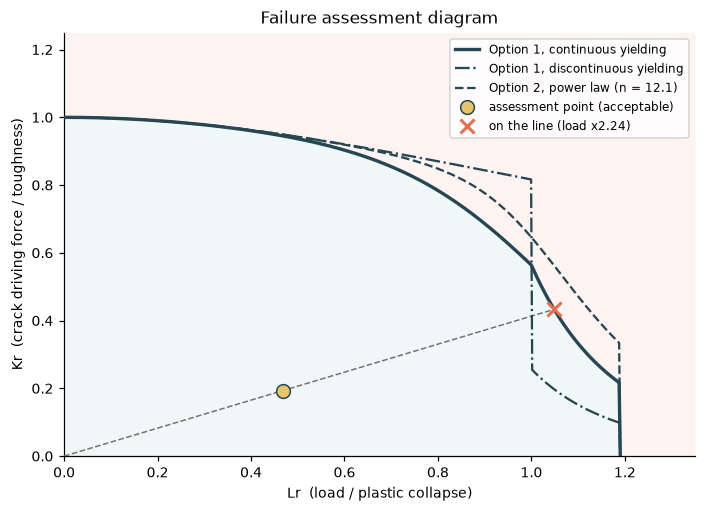

In [2]:
SY, SU, E = 355e6, 490e6, 207e9
plate = cf.FlatPlate(thickness=25e-3, width=0.5)
flaw = cf.SurfaceFlaw(a=3e-3, two_c=20e-3)
steel = cf.Material(SY, SU, E, toughness=90e6, yielding="continuous")
problem = cf.Assessment(plate, flaw, steel, cf.StressState(pm=150e6, pb=30e6))

r = problem.run()
print(f"Lr = {float(r.lr):.3f}   Kr = {float(r.kr):.3f}   Lr,max = {float(r.lr_max):.3f}")
print(f"governing position: {r.positions[int(r.governing_position)]}")
print(f"acceptable: {bool(r.acceptable)}   radial margin (load factor to the line): {float(r.radial_margin):.2f}")

n_lb = float(cf.hardening_exponent_lower_bound(SY, SU))
option1 = problem.curve()
lines = {
    "Option 1, continuous yielding": option1,
    "Option 1, discontinuous yielding": cf.Option1Curve(SY, SU, E, "discontinuous"),
    f"Option 2, power law (n = {n_lb:.1f})": cf.Option2Curve(cf.PowerLaw(offset=0.002, n=n_lb), SY, SU, E),
}
fig, ax = plt.subplots(figsize=(7.4, 5))
fadplot.fad(lines, ax)
fadplot.point(r, ax)
ax.legend(fontsize=8, loc="upper right")
plt.show()

## 2. Map: 14 400 assessments in one vectorised call

Every field of a problem accepts NumPy arrays. A grid of flaw depths (at a fixed shape `2c = 6a`) and
membrane stresses is assessed in a single `run()`. Sizes outside a solution's validity are never
extrapolated (`on_invalid="mask"` flags them). The black line is the direct acceptance test, not a margin
contour; the colour turns at a radial margin of 1.

14400 assessments in 0.08 s; acceptable 10080, invalid 0

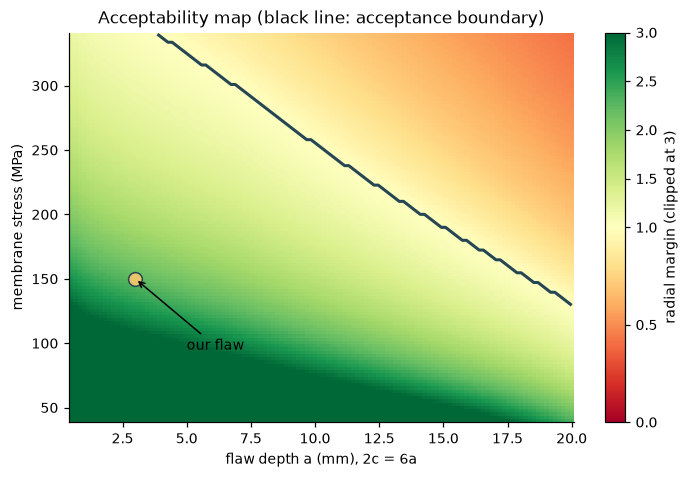

In [3]:
depths = np.linspace(0.5e-3, 20e-3, 120)
stresses = np.linspace(40e6, 340e6, 120)
A, S = np.meshgrid(depths, stresses)
t = time.perf_counter()
grid = problem.with_(flaw=cf.SurfaceFlaw(a=A.ravel(), two_c=6 * A.ravel()),
                     loads=cf.StressState(pm=S.ravel(), pb=30e6)).run(on_invalid="mask")  # fmt: skip
dt = time.perf_counter() - t
ok = grid.acceptable.reshape(A.shape)
valid = grid.valid.reshape(A.shape)
margin = np.where(valid, grid.radial_margin.reshape(A.shape), np.nan)
print(f"{A.size} assessments in {dt:.2f} s; acceptable {int(ok.sum())}, invalid {int((~valid).sum())}")

fig, ax = plt.subplots(figsize=(7.4, 4.6))
norm = TwoSlopeNorm(vmin=0.0, vcenter=1.0, vmax=3.0)
pc = ax.pcolormesh(A * 1e3, S / 1e6, np.clip(margin, 0, 3), cmap="RdYlGn", norm=norm, shading="auto")
fig.colorbar(pc, ax=ax, label="radial margin (clipped at 3)")
ax.contour(A * 1e3, S / 1e6, ok.astype(float), levels=[0.5], colors=fadplot.LINE, linewidths=2)
ax.plot(3.0, 150, "o", ms=9, color=fadplot.POINT, mec=fadplot.LINE)
ax.annotate("our flaw", (3.0, 150), (5, 95), arrowprops={"arrowstyle": "->"})
ax.set(xlabel="flaw depth a (mm), 2c = 6a", ylabel="membrane stress (MPa)",
       title="Acceptability map (black line: acceptance boundary)")  # fmt: skip
plt.show()

## 3. Margins: how far from the boundary?

The same point seen as paths: scaling the load moves it along a ray; growing the flaw bends the path because
the reference stress (Lr) and the crack driving force (Kr) grow at different rates.

reserve factor on primary load  :   2.24
reserve factor on toughness     :   4.88
limiting flaw depth (same shape):  17.76 mm  (from 3 mm today)


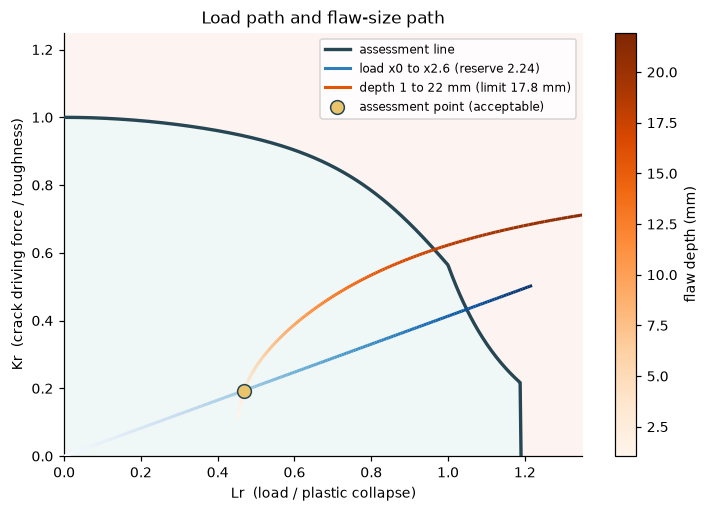

In [4]:
on_load = cf.reserve_factor_on_load(problem)
on_k = cf.reserve_factor_on_toughness(problem)
limit = cf.limiting_flaw_size(problem)
print(f"reserve factor on primary load  : {on_load.value:6.2f}")
print(f"reserve factor on toughness     : {on_k.value:6.2f}")
print(f"limiting flaw depth (same shape): {limit.value * 1e3:6.2f} mm  (from {flaw.a * 1e3:.0f} mm today)")

factors = np.linspace(0.0, 2.6, 200)
sweep = problem.with_(loads=cf.StressState(pm=150e6 * factors, pb=30e6 * factors)).run(on_invalid="mask")
sizes = np.linspace(1e-3, 22e-3, 200)
locus = problem.with_(flaw=cf.SurfaceFlaw(a=sizes, two_c=sizes * 20 / 3)).run(on_invalid="mask")
fig, ax = plt.subplots(figsize=(7.6, 5))
fadplot.fad(option1, ax, title="Load path and flaw-size path")
fadplot.path(sweep.lr, sweep.kr, ax, values=factors, cmap="Blues",
             label=f"load x0 to x2.6 (reserve {on_load.value:.2f})")  # fmt: skip
fadplot.path(locus.lr, locus.kr, ax, values=sizes * 1e3, cmap="Oranges", colorbar_label="flaw depth (mm)",
             label=f"depth 1 to 22 mm (limit {limit.value * 1e3:.1f} mm)")  # fmt: skip
fadplot.point(r, ax, ray=False)
ax.legend(fontsize=8, loc="upper right")
plt.show()

## 4. Probability: the assessment point becomes a density field

Flaw depth, toughness and the extreme membrane stress are random. 100 000 realisations are assessed in one
call; the field is their joint density on the FAD, the white contours enclose 50 %, 90 % and 99 % of the
probability, and every failed realisation is drawn on top. `solve()` then gives a **guaranteed** Monte Carlo
interval and, for small probabilities, a subset-simulation estimate labelled *conditional*.

random variables ('a', 'Kmat', 'pm'); 100,000 realisations, 31 failed


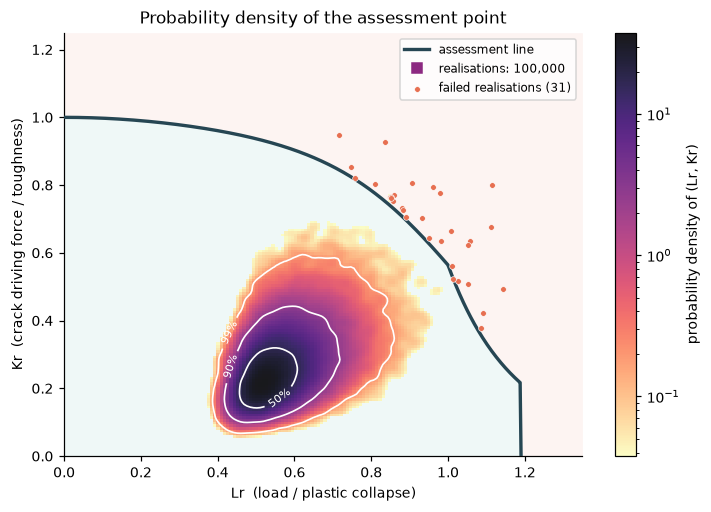

Failure probability per flaw (given that the flaw exists)
Status: conditional
Guaranteed (plain Monte Carlo, 20,000 samples, 6 failures): 99% interval [7.69e-05, 0.000783]
Rare-event estimate (subset simulation, conditional): 0.000281, approximate interval [0.000258, 0.000305]
The rare-event estimate is valid only if no failure region was missed, which cannot be verified from the samples. Values up to the guaranteed upper bound 0.000783 cannot be excluded.
Failure modes (2232 failure samples): fracture 100%, collapse 0%, outside validity 0%


In [5]:
kmat = prob.LogNormal.from_mean_sd(80e6, 20e6, name="Kmat")
pm = prob.Truncated(prob.Gumbel.from_mean_sd(180e6, 25e6), lo=0.0, name="pm")
a_rand = prob.Truncated(prob.LogNormal.from_mean_sd(3e-3, 1.5e-3), hi=12e-3, name="a")
pa = cf.ProbabilisticAssessment(
    cf.Assessment(plate, cf.SurfaceFlaw(a=a_rand, two_c=20e-3), steel.with_(toughness=kmat),
                  cf.StressState(pm=pm, pb=30e6))  # fmt: skip
)
u = np.random.default_rng(7).standard_normal((100_000, pa.vector.size))
cloud = pa.evaluate(u)
failed = ~cloud.acceptable
print(f"random variables {pa.names}; {u.shape[0]:,} realisations, {int(failed.sum())} failed")

fig, ax = plt.subplots(figsize=(7.6, 5))
fadplot.fad(option1, ax, title="Probability density of the assessment point")
fadplot.density(cloud.lr, cloud.kr, ax)
ax.scatter(cloud.lr[failed], cloud.kr[failed], s=14, color=fadplot.FAIL, edgecolor="white", lw=0.4, zorder=5,
           label=f"failed realisations ({int(failed.sum())})")  # fmt: skip
ax.legend(fontsize=8, loc="upper right")
plt.show()

res = pa.solve(seed=0, n_explore=20_000, replicates=4, samples_per_level=2000)
print(res.summary())

## 5. An uncertain assessment line: the exceedance field

Yield and tensile strength scatter, and with them the Option 2 line. The background is the probability that
a point at each (Lr, Kr) is not acceptable over that scatter, with the 5 %, 50 % and 95 % lines; the black
contours are the point density from section 4. Failure probability lives where the two fields meet.
(Simplification for the picture: the points are referred to the nominal yield strength.)

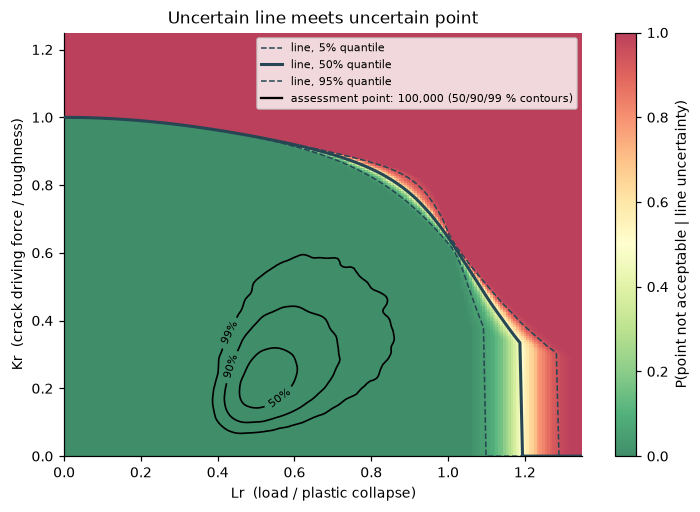

In [6]:
rng = np.random.default_rng(3)
sy_s = SY * np.exp(rng.normal(0.0, 0.07, 300))
su_s = np.maximum(sy_s * 1.12, SU * np.exp(rng.normal(0.0, 0.05, 300)))
n_s = cf.hardening_exponent_lower_bound(sy_s, su_s)
line_samples = [
    cf.Option2Curve(cf.PowerLaw(offset=0.002, n=float(n)), float(sy), float(su), E)
    for sy, su, n in zip(sy_s, su_s, n_s, strict=True)
]
fig, ax = plt.subplots(figsize=(7.6, 5))
fadplot.fad(line_samples[0], ax, shade=False, title="Uncertain line meets uncertain point")
ax.lines[0].remove()  # the field and its quantile lines replace the single line
fadplot.exceedance_field(line_samples, ax)
fadplot.density(cloud.lr, cloud.kr, ax, fill=False, contour_color="black", label="assessment point")
ax.legend(fontsize=7, loc="upper right")
plt.show()

## 6. Grow: fatigue moves every point towards the line

Constant-amplitude membrane range 70 MPa (plus 10 MPa bending) at 10^5 cycles a year, with the two-stage
upper-bound law for steel in air. **First:** the growing flaw assessed against four candidate fracture loads;
the cross is where each path reaches the line (the life at that load). **Then:** the same growth with random
toughness and load: the whole density field drifts into the unacceptable region.

breakthrough (leak) at 6.5 years


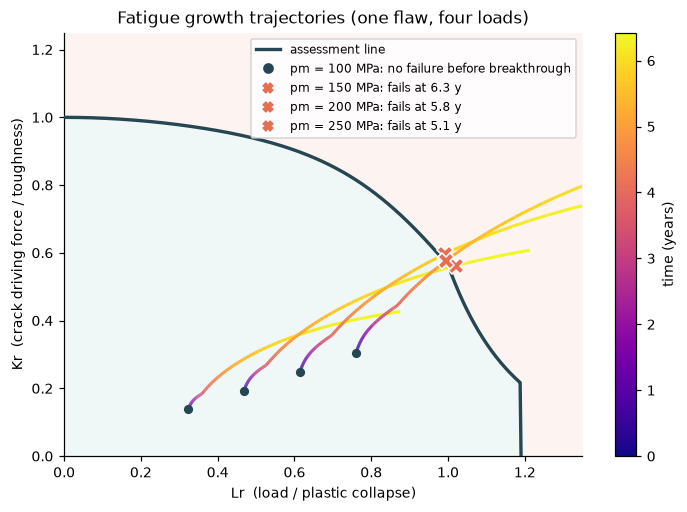

In [7]:
law = steel_in_air()
spectrum = Spectrum.repeating([(70e6, 10e6, 1.0)], cycles_per_year=1e5)
fixed = ExtremeLoad(prob.Uniform(150e6, 150.001e6), reference_period_years=0.25)  # fixed load, fine steps
h = TimeDependentAssessment(problem, law, spectrum, fixed, times=np.arange(0.25, 30.01, 0.25),
                            leak_is_failure=False).grow()  # fmt: skip
print(f"breakthrough (leak) at {h.t_leak:.1f} years")
surface = h.kind == SURFACE
t_s = np.append(0.0, h.times[surface])
a_s = np.append(3e-3, h.a[surface])
c_s = np.append(10e-3, h.c[surface])

fig, ax = plt.subplots(figsize=(7.6, 5))
fadplot.fad(option1, ax, title="Fatigue growth trajectories (one flaw, four loads)")
for i, s_check in enumerate((100e6, 150e6, 200e6, 250e6)):
    pts = problem.with_(flaw=cf.SurfaceFlaw(a=a_s, two_c=2 * c_s),
                        loads=cf.StressState(pm=s_check, pb=30e6)).run(on_invalid="mask")  # fmt: skip
    fadplot.path(pts.lr, pts.kr, ax, values=t_s, cmap="plasma", colorbar_label="time (years)" if i == 0 else None)
    bad = np.flatnonzero(~pts.acceptable)
    life = f"fails at {t_s[bad[0]]:.1f} y" if bad.size else "no failure before breakthrough"
    ax.plot(pts.lr[0], pts.kr[0], "o", ms=5, color=fadplot.LINE, zorder=7)
    if bad.size:
        ax.plot(pts.lr[bad[0]], pts.kr[bad[0]], "X", ms=10, color=fadplot.FAIL, mec="white", zorder=7)
    ax.plot([], [], "X" if bad.size else "o", color=fadplot.FAIL if bad.size else fadplot.LINE,
            label=f"pm = {s_check / 1e6:.0f} MPa: {life}")  # fmt: skip
ax.legend(fontsize=8, loc="upper right")
plt.show()

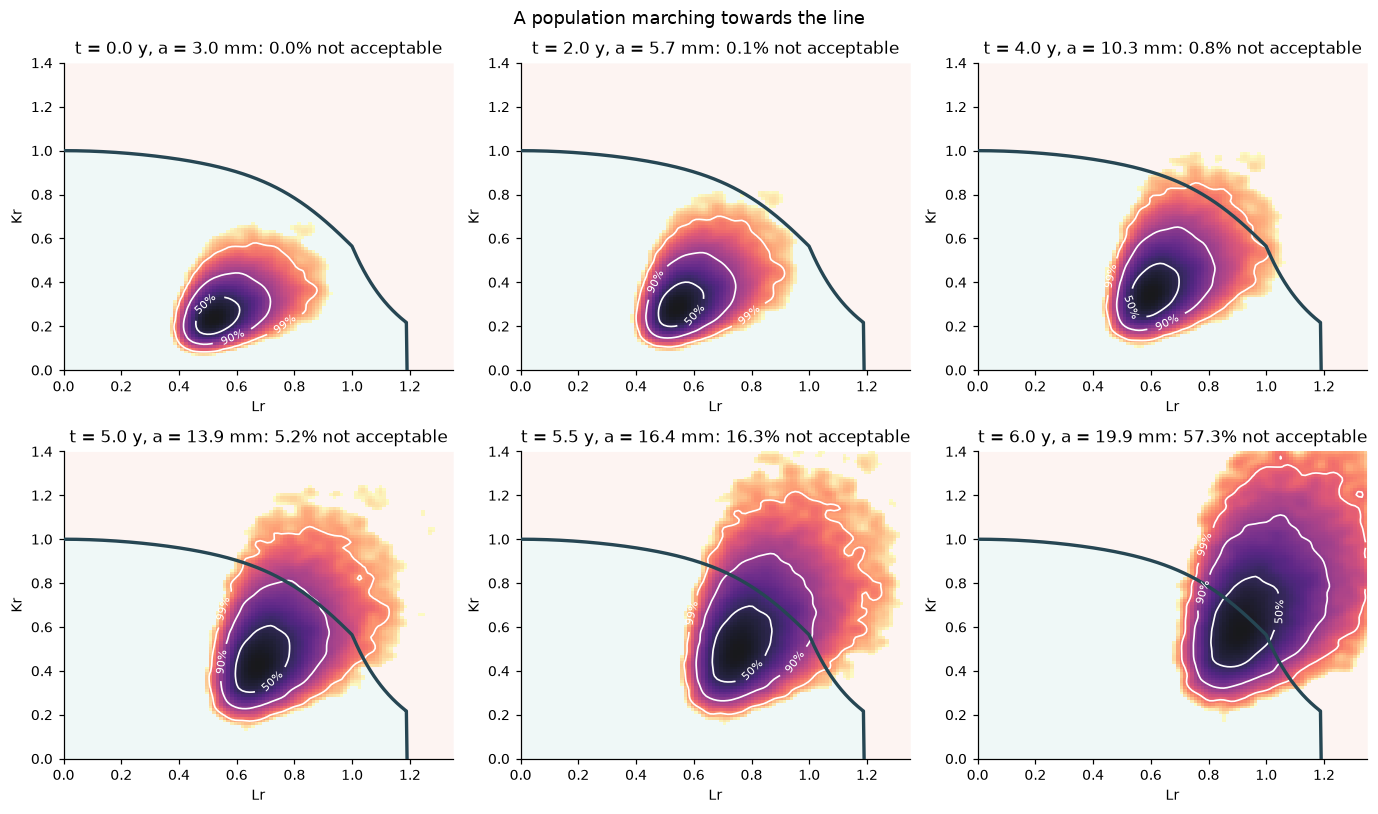

In [8]:
pa_t = cf.ProbabilisticAssessment(cf.Assessment(plate, flaw, steel.with_(toughness=kmat), cf.StressState(pm=pm, pb=30e6)))
u_t = np.random.default_rng(11).standard_normal((40_000, pa_t.vector.size))
realised = pa_t.realise(u_t)
panels = []
for year in (0.0, 2.0, 4.0, 5.0, 5.5, 6.0):
    i = int(np.argmin(np.abs(t_s - year)))
    real = realised.with_(flaw=cf.SurfaceFlaw(a=float(a_s[i]), two_c=2 * float(c_s[i]))).run(on_invalid="mask")
    share = float((~real.acceptable).mean())

    def draw(ax, real=real):
        fadplot.fad(option1, ax, title=None, kr_extent=1.4)
        fadplot.density(real.lr, real.kr, ax, colorbar=False, bins=110)
        ax.set(xlabel="Lr", ylabel="Kr")

    panels.append((f"t = {t_s[i]:.1f} y, a = {a_s[i] * 1e3:.1f} mm: {share:.1%} not acceptable", draw))
fig = fadplot.small_multiples(panels, ncols=3)
fig.suptitle("A population marching towards the line", y=1.02, fontsize=12)
plt.show()

## 7. Over the life: failure probability with and without an inspection

Now the initial depth is random too and every flaw grows. An inspection at year 5 with a log-logistic
probability of detection (50 % at 3 mm) repairs what it finds. The band is the bracket between the two ways
of pairing a step's growth with its maximum load; small samples keep this quick.

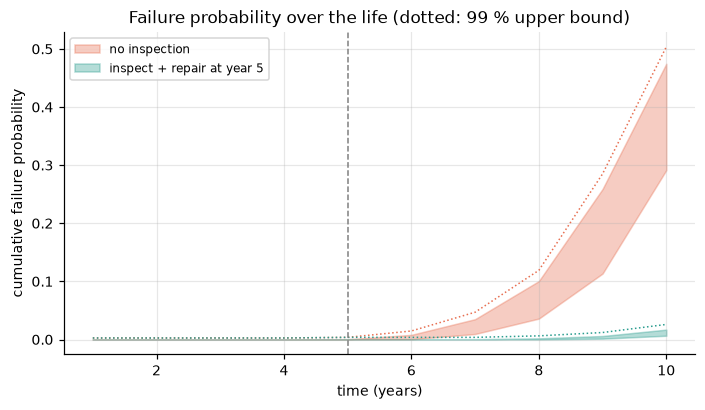

In [9]:
a0 = prob.Truncated(prob.LogNormal.from_mean_sd(1.5e-3, 0.8e-3), hi=10e-3, name="a0")
population = cf.Assessment(plate, cf.SurfaceFlaw(a=a0, two_c=15e-3), steel.with_(toughness=kmat),
                           cf.StressState(pm=150e6))  # fmt: skip
annual_max = ExtremeLoad(prob.Truncated(prob.Gumbel.from_mean_sd(150e6, 15e6), lo=0.0), reference_period_years=1.0)
common = {"times": range(1, 11), "leak_is_failure": False}
runs = {
    "no inspection": TimeDependentAssessment(population, law, spectrum, annual_max, **common),
    "inspect + repair at year 5": TimeDependentAssessment(
        population, law, spectrum, annual_max, **common,
        inspections=[Inspection(time=5.0, pod=LogLogisticPoD(a50=3e-3, beta=4.0), action="repair")],
    ),
}  # fmt: skip
life = {k: v.solve(seed=0, samples=2000) for k, v in runs.items()}

fig, ax = plt.subplots(figsize=(7.4, 3.8))
for (name, rr), colour in zip(life.items(), (fadplot.FAIL, fadplot.SAFE), strict=True):
    tt = np.asarray(rr.times)
    ax.fill_between(tt, rr.cumulative_lower.value, rr.cumulative_upper.value, color=colour, alpha=0.35, label=name)
    ax.plot(tt, rr.cumulative_upper.upper, color=colour, ls=":", lw=1)
ax.axvline(5, color="0.5", lw=1, ls="--")
ax.grid(alpha=0.3)
ax.set(xlabel="time (years)", ylabel="cumulative failure probability",
       title="Failure probability over the life (dotted: 99 % upper bound)")  # fmt: skip
ax.legend(fontsize=8)
plt.show()

## 8. Audit: what did that result rest on?

Every result carries a trace: the equations used, the primary reference each one comes from, and its
verification status in the knowledge base (`unverified` < `self-consistent` < `cross-checked` <
`fe-verified`). `Assessment.run(strict=True)` refuses a result that rests on anything below `cross-checked`.

In [10]:
for d in r.trace.dependencies():
    print(f"{d['id']}  [{d['kb_status']}]")
    print(textwrap.indent(textwrap.fill(str(d["citation"]), 100), "    "))
print(f"\nshowcase ran in {time.perf_counter() - T0:.0f} s")

fad.cutoff  [self-consistent]
    Plastic collapse cut-off Lr,max from yield and tensile strength [no primary reference given by the
    source standard]
fad.kr  [self-consistent]
    Fracture ratio Kr with additive rho or multiplying V [no primary reference given by the source
    standard]
k.general  [self-consistent]
    General form K = (Y sigma) sqrt(pi a) with primary and secondary parts [no primary reference given
    by the source standard]
fad.option1.continuous  [self-consistent]
    Option 1 assessment line, continuous yielding [no primary reference given by the source standard]
k.plate.surface  [cross-checked]
    Semi-elliptical surface flaw in a plate, membrane and bending: Newman, J.C. and Raju, I.S. Stress
    intensity factor equations for cracks in three-dimensional finite bodies subjected to tension and
    bending loads. NASA Technical Memorandum 85793. (as cited by the source standard)
sref.plate.surface  [cross-checked]
    Reference stress, surface flaw in a plat

## Where next

* `19_fad_gallery` for more FAD graphics; examples `01`–`18` for Option 2 from measured curves, secondary and
  residual stress, cylinders, embedded flaws, FORM/SORM, subset simulation, dependence, partial factors,
  inspection updating.
* **Experimental:** the WARP3D finite-element backend and the Option 3 emulator (examples `15`–`17`).
* Theory manual `docs/manual/theory/`, user manual `docs/manual/user/`.

> **Reminder:** research software, not verified or validated, in development. Not for real-world use.